# Fir and Linear

`Fir` and `Linear` are the two layers with weights that most models are made
of. Both compute a weighted sum plus a bias - but along different axes:

| | `Fir` | `Linear` |
|---|---|---|
| sums over | the **window** `T`: the samples of a signal in time | the **dims** `D`: the features of one sample |
| keeps | each feature apart | each sample of the window apart |
| shape | `T=n, D=(d,)` -> `T=1, D=(d,)` (or `(d, features)`) | `T=n, D=(d,)` -> `T=n, D=(features,)` |
| models | a filter, an impulse response, an ARX term | a static map, a layer of a network |

This tutorial shows both on numbers you can check by hand, then how to give
them **custom weights** - known coefficients, shared or frozen kernels,
initializers - and an identification of an impulse response.

In [1]:
import os

# Pick the Keras backend before nnodely (or Keras) is imported:
# "tensorflow" (the default), "torch" or "jax".
os.environ.setdefault("KERAS_BACKEND", "tensorflow")

import keras
import matplotlib.pyplot as plt
import numpy as np

from nnodely import (
    DataLoader,
    Fir,
    Input,
    Linear,
    Modely,
    Output,
    Parameter,
    Tanh,
    set_seed,
)

set_seed(0)


def run(inputs, outputs, data):
    """Build a model of the given outputs and run it on one sample."""
    model = Modely("probe", inputs=inputs, outputs=outputs).build()
    results = model(
        {name: np.asarray(value, "float32")[None] for name, value in data.items()}
    )
    return {
        name: keras.ops.convert_to_numpy(value)[0] for name, value in results.items()
    }

## `Fir`: a weighted sum along the window

With a window of `n` samples `x[t-n+1], ..., x[t]`, oldest first, a `Fir` with
kernel `k` and bias `b` computes **one** output sample:

$$y[t] = \sum_{i=0}^{n-1} k_i\,x[t-n+1+i] + b$$

The kernel is a column per output channel, its rows the samples of the window,
oldest first. Here it is given explicitly, as a `Parameter`, to check the sum by
hand:

In [2]:
x = Input("x", tw=4)
kernel = Parameter("k", value=[[0.1], [0.2], [0.3], [0.4]])  # (window, features)
fir = Fir(features=1, kernel=kernel, bias=False)([x])
print("shape:", fir.shape)

window = np.array([[1.0], [2.0], [3.0], [4.0]])
result = run([x], [Output("fir", fir)], {"x": window})
print(
    "Fir:  ",
    result["fir"].ravel(),
    " by hand:",
    window.ravel() @ np.array([0.1, 0.2, 0.3, 0.4]),
)

shape: Shape(S=(), T=1, D=(1,))
Fir:   [3.]  by hand: 3.0


`features=n` gives `n` filters of the same window - `n` output channels, a
kernel of `n` columns. On a signal of several features, each feature is
filtered **on its own** (features are never mixed), with a kernel of its own,
and the channels become a new last dim axis; `shared_kernel=True` applies one
kernel to every feature:

In [3]:
v = Input("v", dim=3, tw=4)
for label, layer in [
    ("Fir(features=1) on x", Fir(features=1)([x])),
    ("Fir(features=2) on x", Fir(features=2)([x])),
    ("Fir(features=1) on v", Fir(features=1)([v])),
    ("Fir(features=2) on v", Fir(features=2)([v])),
    ("shared kernel on v", Fir(features=2, shared_kernel=True)([v])),
]:
    print(f"{label:22s} {layer.shape}")

Fir(features=1) on x   Shape(S=(), T=1, D=(1,))
Fir(features=2) on x   Shape(S=(), T=1, D=(2,))
Fir(features=1) on v   Shape(S=(), T=1, D=(3,))
Fir(features=2) on v   Shape(S=(), T=1, D=(3, 2))
shared kernel on v     Shape(S=(), T=1, D=(3, 2))


## `Linear`: a weighted sum of the features

A `Linear` maps the features of each sample, $y = W^\top x + b$, the same map for
every sample of the window and every step of a sequence. With `features=n` it
gives `n` outputs per sample:

In [4]:
weights = Parameter(
    "W", value=[[1.0, 0.0], [0.0, 1.0], [1.0, -1.0]]
)  # (3 inputs, 2 outputs)
bias = Parameter("b", value=[0.5, 0.0])
lin = Linear(features=2, kernel=weights, bias=bias)([v])
print("shape:", lin.shape)

samples = np.arange(12.0).reshape(4, 3)  # 4 samples of 3 features
result = run([v], [Output("lin", lin)], {"v": samples})
print(result["lin"])
print("by hand:")
print(samples @ np.array([[1, 0], [0, 1], [1, -1]]) + [0.5, 0])

shape: Shape(S=(), T=4, D=(2,))
[[ 2.5 -1. ]
 [ 8.5 -1. ]
 [14.5 -1. ]
 [20.5 -1. ]]
by hand:
[[ 2.5 -1. ]
 [ 8.5 -1. ]
 [14.5 -1. ]
 [20.5 -1. ]]


On a matrix-valued signal, `Linear` maps all its dims at once; `axis=k` maps
only dim axis `k`, with a matrix per position of the others - or one matrix for
all with `shared_kernel=True`:

In [5]:
grid = Input("grid", dim=(2, 3), tw=1)
for label, layer in [
    ("Linear(5)", Linear(features=5)([grid])),
    ("Linear(5, axis=1)", Linear(features=5, axis=1)([grid])),
    ("Linear(5, axis=0)", Linear(features=5, axis=0)([grid])),
]:
    print(f"{label:18s} {layer.shape}")

Linear(5)          Shape(S=(), T=1, D=(5,))
Linear(5, axis=1)  Shape(S=(), T=1, D=(2, 5))
Linear(5, axis=0)  Shape(S=(), T=1, D=(5, 3))


## Fir or Linear?

`Fir` looks back in time, `Linear` looks across the features: they answer
different questions, and models chain them.

- **A dynamic response** - an output depending on the past of an input - is a
  `Fir` over the input's window.
- **A static map** - an output depending on the current values - is a
  `Linear`, and a network is `Linear` layers with activations between them.
- **Several inputs, filtered**: `Linear` mixes them sample by sample, then a
  `Fir` filters the mix (or a `Fir` per input, summed).

In [6]:
u = Input("u", dim=3, tw=20)
mixed_then_filtered = Fir(features=1)(
    [Linear(features=1)([u])]
)  # 3 inputs -> 1, filtered
network = Linear(features=1)([Tanh()(Linear(features=16)([Input("p", dim=3, tw=1)]))])
print("mix, then filter:", mixed_then_filtered.shape)
print("network:         ", network.shape)

mix, then filter: Shape(S=(), T=1, D=(1,))
network:          Shape(S=(), T=1, D=(1,))


## Custom weights

`kernel=` and `bias=` take:

- a `Parameter` of the weight's shape - known values, or values shared with
  other layers;
- a Keras initializer, by name (`"zeros"`, `"ones"`, `"glorot_uniform"`, the
  default kernel) or as an object - the layer then makes a `Parameter` named
  `<layer>_kernel` / `<layer>_bias`;
- `bias=False` leaves the bias out.

The shapes:

| Layer | kernel | bias |
|---|---|---|
| `Fir(features=f)` on `D=(d,)`, window `n` | `(d, n, f)`, `(n, f)` for a scalar or a shared kernel | `(d, f)`, `(f,)` |
| `Linear(features=f)` on `D=(d,)` | `(d, f)` | `(f,)` |

### A filter with known coefficients

A moving average over 5 samples is a `Fir` with a kernel of `1/5` everywhere.
Created **frozen**, training leaves it as it is:

In [7]:
signal = Input("signal", tw=5)
average = Fir(
    features=1,
    kernel=Parameter("average_kernel", value=np.full((5, 1), 0.2), trainable=False),
    bias=False,
    name="moving_average",
)([signal])
result = run(
    [signal], [Output("avg", average)], {"signal": [[1.0], [2.0], [3.0], [4.0], [5.0]]}
)
print(result["avg"].ravel())

[3.]


### Shared weights

Two layers given the **same** `Parameter` use one set of weights: the same
filter applied to a left and a right sensor, trained by both:

In [8]:
shared_kernel = Parameter("sensor_kernel", dim=(8, 1))  # drawn at random, then trained
left, right = Input("left", tw=8), Input("right", tw=8)
pair = Modely(
    "pair",
    inputs=[left, right],
    outputs=[
        Output("left_f", Fir(features=1, kernel=shared_kernel, bias=False)([left])),
        Output("right_f", Fir(features=1, kernel=shared_kernel, bias=False)([right])),
    ],
).build()
pair.parameters  # one kernel

┏━━━━━┳━━━━━━━━━━━━━━━┳━━━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━┓
┃ idx ┃ parameter     ┃ seq ┃ tw   ┃ dim    ┃ values ┃ trainable ┃
┡━━━━━╇━━━━━━━━━━━━━━━╇━━━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━┩
│ 0   │ sensor_kernel │ ()  │ None │ (8, 1) │ 8      │ yes       │
├─────┼───────────────┼─────┼──────┼────────┼────────┼───────────┤
│     │ total         │     │      │        │ 8      │ 8         │
└─────┴───────────────┴─────┴──────┴────────┴────────┴───────────┘

Calling one layer **object** on two streams shares its weights in the same way:
`f = Fir(features=1)`, then `f([left])` and `f([right])`.

### Initializers

A name or a Keras initializer object, for the kernel and the bias:

In [9]:
z = Input("z", dim=2, tw=1)
layers = Modely(
    "inits",
    inputs=[z],
    outputs=[
        Output(
            "ones", Linear(features=2, kernel="ones", bias="zeros", name="ones")([z])
        ),
        Output(
            "small",
            Linear(
                features=2,
                kernel=keras.initializers.RandomNormal(stddev=0.01),
                name="small",
            )([z]),
        ),
        Output("nobias", Linear(features=2, bias=False, name="nobias")([z])),
    ],
).build()
print(layers.parameters["ones_kernel"].value_numpy)
layers.parameters

[[1. 1.]
 [1. 1.]]


┏━━━━━┳━━━━━━━━━━━━━━━┳━━━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━┳━━━━━━━━━━━┓
┃ idx ┃ parameter     ┃ seq ┃ tw   ┃ dim    ┃ values ┃ trainable ┃
┡━━━━━╇━━━━━━━━━━━━━━━╇━━━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━╇━━━━━━━━━━━┩
│ 0   │ ones_kernel   │ ()  │ None │ (2, 2) │ 4      │ yes       │
│ 1   │ ones_bias     │ ()  │ None │ (2,)   │ 2      │ yes       │
│ 2   │ small_kernel  │ ()  │ None │ (2, 2) │ 4      │ yes       │
│ 3   │ small_bias    │ ()  │ None │ (2,)   │ 2      │ yes       │
│ 4   │ nobias_kernel │ ()  │ None │ (2, 2) │ 4      │ yes       │
├─────┼───────────────┼─────┼──────┼────────┼────────┼───────────┤
│     │ total         │     │      │        │ 16     │ 16        │
└─────┴───────────────┴─────┴──────┴────────┴────────┴───────────┘

## Identifying an impulse response

An unknown linear system answers its input through an impulse response `h`:
the output is the input convolved with `h`. A `Fir` over a window as long as the
response **is** that convolution, so training it on the input and output finds
`h` - each kernel row is one sample of the response, oldest first, so the
kernel is `h` reversed.

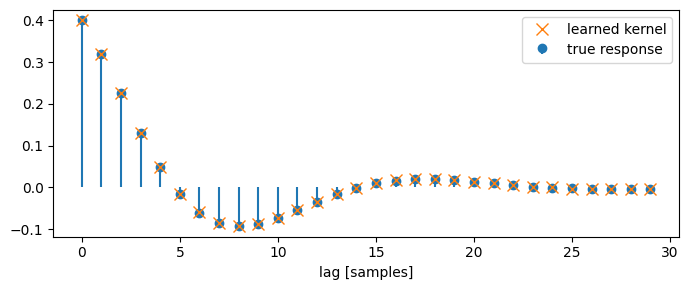

In [10]:
n = 30
t = np.arange(n)
h = 0.4 * np.exp(-t / 6.0) * np.cos(t / 3.0)  # the unknown response
rng = np.random.default_rng(0)
u_data = rng.standard_normal(4000)
y_data = np.convolve(u_data, h)[: len(u_data)] + 0.01 * rng.standard_normal(len(u_data))

u_in = Input("u", tw=n)
filtered = Fir(features=1, bias=False, name="response")([u_in])
response = Output("y", filtered)
system = Modely("system", inputs=[u_in], outputs=[response])
system.minimize("output", response, Input("y_meas", tw=1))
system.build()
system.train(
    DataLoader(system, source={"u": u_data, "y_meas": y_data}),
    epochs=30,
    batch_size=64,
    lr=1e-2,
    printer=None,
)

learned = system.parameters["response_kernel"].value_numpy.ravel()[
    ::-1
]  # newest sample first
plt.figure(figsize=(7, 3))
plt.stem(t, h, linefmt="C0-", markerfmt="C0o", basefmt=" ", label="true response")
plt.plot(t, learned, "C1x", ms=8, label="learned kernel")
plt.xlabel("lag [samples]")
plt.legend()
plt.tight_layout()

After the build, the weights are also reachable from the stream a layer
returned - `stream.kernel` and `stream.bias` are the Keras variables:

In [11]:
print(filtered.kernel.shape, "bias:", filtered.bias)
same = np.allclose(
    keras.ops.convert_to_numpy(filtered.kernel),
    system.parameters["response_kernel"].value_numpy,
)
print("the Parameter's value:", same)

(30, 1) bias: None
the Parameter's value: True


## Summary

| Task | Code |
|---|---|
| Filter a window | `Fir(features=1)([x])`: `T=n` -> `T=1` |
| Several filters | `Fir(features=k)`; one kernel for every feature: `shared_kernel=True` |
| Map the features | `Linear(features=k)([x])`: window kept; one dim axis: `axis=` |
| A network | `Linear(...)` with activations between |
| Known weights | `kernel=Parameter(value=...)`, `bias=Parameter(...)`, `bias=False` |
| Fixed weights | `Parameter(..., trainable=False)`, or `.freeze()` |
| Shared weights | the same `Parameter`, or the same layer object |
| Initializers | `kernel="zeros"`, `kernel=keras.initializers.RandomNormal(...)` |
| Read them | `model.parameters["<layer>_kernel"]` |

Next: [Fuzzify and LocalModel](09_fuzzify_localmodel.ipynb).